# Extra: reconocimiento de entidades (NER) por categoría

**Objetivo:** identificar las entidades más frecuentes (personas, organizaciones y lugares) que aparecen en los titulares de cada una de las 4 categorías: política, economía, deportes y ciencia y tecnología.

**Modelo:** [`mrm8488/bert-spanish-cased-finetuned-ner`](https://huggingface.co/mrm8488/bert-spanish-cased-finetuned-ner), un BETO (BERT en español) ajustado para NER con CoNLL-2002. Etiquetas: `PER`, `ORG`, `LOC` y `MISC`. Se ejecuta en CPU.

In [1]:
import re
from pathlib import Path

import pandas as pd
import plotly.express as px
from IPython.display import Image, display
from transformers import pipeline

DATOS = Path("datos")
MODELO = Path("modelo")

noticias = pd.read_csv(DATOS / "noticias.csv")
print(noticias.shape)
print(noticias["etiqueta"].value_counts())

ner = pipeline(
    "ner",
    model="mrm8488/bert-spanish-cased-finetuned-ner",
    aggregation_strategy="simple",
    device=-1,  # CPU
)

C:\Users\Asus\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(385, 7)
etiqueta
deportes              101
politica               96
ciencia_tecnologia     95
economia               93
Name: count, dtype: int64


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 18180.10it/s]


[transformers] BertForTokenClassification LOAD REPORT from: mrm8488/bert-spanish-cased-finetuned-ner
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## Aplicar el modelo a los titulares

Con `aggregation_strategy="simple"` el pipeline a veces corta una palabra en fragmentos (`##idad de Lima`, `##em`). Para unirlos se usan los offsets de cada entidad: se extiende el tramo hasta los bordes de palabra del titular, se fusionan los tramos que se solapan o se tocan y el texto final se toma del titular original (score = promedio de los fragmentos; tipo = el del fragmento con mayor score). Después se normalizan espacios y se descartan entidades con score < 0.80, de una sola letra o que empiecen con `##`.

In [2]:
UMBRAL = 0.80


def extender(texto, inicio, fin):
    """Extiende [inicio, fin) hasta los bordes de palabra."""
    while inicio > 0 and texto[inicio - 1].isalnum():
        inicio -= 1
    while fin < len(texto) and texto[fin].isalnum():
        fin += 1
    return inicio, fin


def entidades_de(texto, crudas):
    tramos = []
    for e in sorted(crudas, key=lambda e: e["start"]):
        inicio, fin = extender(texto, e["start"], e["end"])
        frag = {"inicio": inicio, "fin": fin, "partes": [e]}
        if tramos and inicio <= tramos[-1]["fin"]:  # se solapa o toca: unir
            tramos[-1]["fin"] = max(tramos[-1]["fin"], fin)
            tramos[-1]["partes"].append(e)
        else:
            tramos.append(frag)
    salida = []
    for t in tramos:
        entidad = re.sub(r"\s+"," ", texto[t["inicio"]:t["fin"]]).strip(" .,:;\"'“”‘’¿?¡!")
        mejor = max(t["partes"], key=lambda e: e["score"])
        score = sum(float(e["score"]) for e in t["partes"]) / len(t["partes"])
        salida.append({"entidad": entidad, "tipo": mejor["entity_group"], "score": round(score, 4)})
    return salida


resultados = ner(noticias["titular"].tolist(), batch_size=16)

filas = []
for (_, fila), crudas in zip(noticias.iterrows(), resultados):
    for e in entidades_de(fila["titular"], crudas):
        filas.append({"url": fila["url"], "etiqueta": fila["etiqueta"], **e})

todas = pd.DataFrame(filas, columns=["url", "etiqueta", "entidad", "tipo", "score"])
entidades = todas[
    (todas["score"] >= UMBRAL)
    & (todas["entidad"].str.len() > 1)
    & (~todas["entidad"].str.startswith("##"))
].reset_index(drop=True)

entidades.to_csv(DATOS / "entidades.csv", index=False)
print(f"Entidades antes del filtro: {len(todas)} · después: {len(entidades)}")
print(f"Titulares con al menos una entidad: {entidades['url'].nunique()} de {len(noticias)}")
entidades["tipo"].value_counts()

Entidades antes del filtro: 843 · después: 724
Titulares con al menos una entidad: 343 de 385


tipo
ORG     269
PER     190
MISC    170
LOC      95
Name: count, dtype: int64

## Top 10 entidades por tipo y categoría

In [3]:
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
TIPOS = ["PER", "ORG", "LOC"]

conteo = (
    entidades[entidades["tipo"].isin(TIPOS)]
    .groupby(["etiqueta", "tipo", "entidad"]).size()
    .rename("frecuencia").reset_index()
    .sort_values(["etiqueta", "tipo", "frecuencia", "entidad"], ascending=[True, True, False, True])
)
top10 = conteo.groupby(["etiqueta", "tipo"]).head(10)

for cat in CATEGORIAS:
    tabla = {}
    for tipo in TIPOS:
        sub = top10[(top10["etiqueta"] == cat) & (top10["tipo"] == tipo)]
        tabla[tipo] = [f"{e} ({n})" for e, n in zip(sub["entidad"], sub["frecuencia"])]
    largo = max(len(v) for v in tabla.values())
    tabla = pd.DataFrame({k: v + [""] * (largo - len(v)) for k, v in tabla.items()})
    tabla.index = range(1, largo + 1)
    print(f"=== {cat} ===")
    display(tabla)

=== politica ===


,PER,ORG,LOC
1,Keiko Fujimori (11),Senado (12),Perú (8)
2,Carlos Mesía (4),Congreso (9),China (1)
3,León XIV (4),Comisión de Constitución (7),EE.UU (1)
4,Álvaro Vargas Llosa (4),Comisión de Constitución del Senado (4),El Salvador (1)
5,Alfonso López Chau (3),Poder Judicial (3),La Libertad (1)
6,César Astudillo (3),Ahora Nación (2),Lima (1)
7,Daniel Barragán (3),Alcaldía de Lima (2),
8,Fernando Vivas (3),Diputados (2),
9,Graciela Chipana (3),Ejecutivo (2),
10,César Acuña (2),Estados Unidos (2),


=== economia ===


,PER,ORG,LOC
1,Alberto Goachet (1),Estados Unidos (3),Perú (13)
2,Beatriz Boza (1),Gobierno (3),Texas (3)
3,Daniel Velandia (1),Indecopi (3),EE.UU (2)
4,Eduardo Grisolle (1),BTS (2),Medio Oriente (2)
5,Elmer Cuba (1),MTC (2),Amazonía (1)
6,Gilat (1),ONP (2),Arabia Saudí (1)
7,Justin Trudeau (1),Adex (1),Canadá (1)
8,Luis Felipe Gazitúa (1),Banbif (1),Cono Sur de América Latina (1)
9,Mario Gonzales (1),Biministro de Economía y Minería de Chile (1),Costa Rica (1)
10,Pablo Nano (1),Coca-Cola (1),Estados Unidos (1)


=== deportes ===


,PER,ORG,LOC
1,Annia Cillóniz (5),Alianza (6),Cusco (3)
2,Ignacio Buse (3),Universitario (6),Matute (3)
3,Lamine Yamal (3),Alianza Lima (5),Perú (2)
4,André Martínez (2),Atlético Grau (5),Argentina (1)
5,Diego Elías (2),Barcelona (5),Ayacucho (1)
6,Eduardo Castro (2),Real Betis (5),Brasil (1)
7,Lionel Messi (2),Alianza Atlético (4),Costa Verde (1)
8,Ortiz Bisso (2),River Plate (4),Europa (1)
9,Piero Cari (2),Inter Miami (3),La Cartuja (1)
10,Quevedo (2),Palmeiras (3),La Punta (1)


=== ciencia_tecnologia ===


,PER,ORG,LOC
1,Francis Halzen (3),Google (5),Perú (7)
2,Trump (2),IA (4),América Latina (2)
3,Ben Affleck (1),Apple (3),Latinoamérica (2)
4,Bill Gates (1),Microsoft (3),Siberia (2)
5,Claude (1),Estados Unidos (2),2027 (1)
6,Demetrio Pacheco (1),Meta (2),Alemania (1)
7,Edgar (1),OpenAI (2),Andes (1)
8,Epic (1),Adobe (1),Antártida (1)
9,Halzen (1),Alibaba (1),Finlandia (1)
10,Henri Kagan (1),Atari (1),Japón (1)


## Personas y organizaciones más mencionadas por categoría

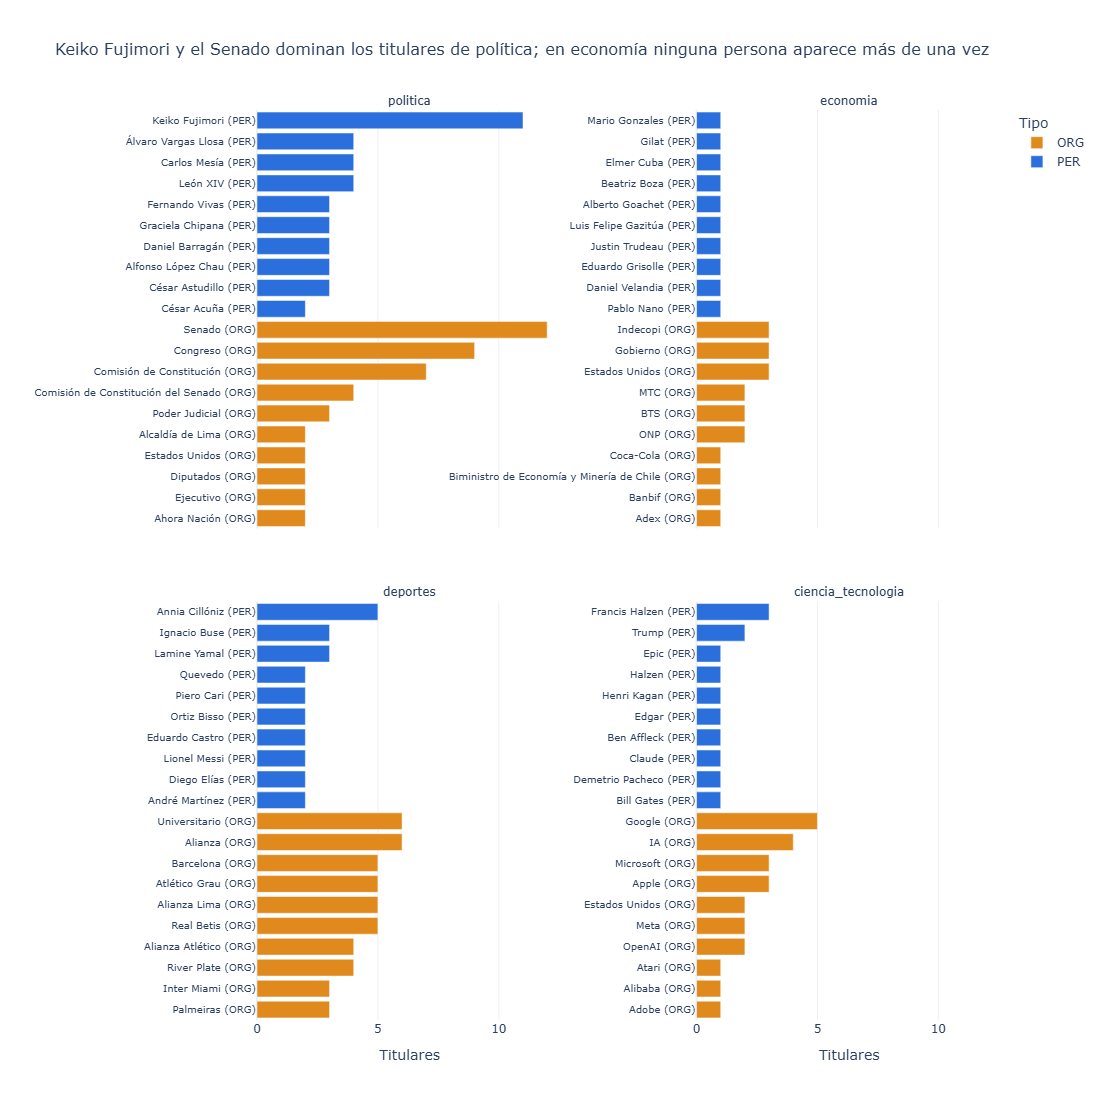

In [4]:
TITULO_GRAFICO = (
    "Keiko Fujimori y el Senado dominan los titulares de política; "
    "en economía ninguna persona aparece más de una vez"
)

graf = top10[top10["tipo"].isin(["PER", "ORG"])].copy()
graf["entidad_tipo"] = graf["entidad"] + " (" + graf["tipo"] + ")"

fig = px.bar(
    graf.sort_values("frecuencia"),
    x="frecuencia", y="entidad_tipo", color="tipo",
    facet_col="etiqueta", facet_col_wrap=2, facet_col_spacing=0.18, facet_row_spacing=0.08,
    category_orders={"etiqueta": CATEGORIAS},
    color_discrete_map={"PER": "#2a6fdb", "ORG": "#e08a1e"},
    labels={"frecuencia": "Titulares", "entidad_tipo": "", "tipo": "Tipo"},
    title=TITULO_GRAFICO,
    height=1100, width=1100,
)
fig.update_yaxes(matches=None, showticklabels=True, tickfont_size=10)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(template="plotly_white", title_font_size=16, margin=dict(t=110, l=10, r=10))

ruta_png = MODELO / "ner_top_entidades.png"
fig.write_image(ruta_png, scale=1)
display(Image(filename=str(ruta_png)))

## Observaciones y limitación

**Observaciones**
1. **Política es la categoría más concentrada en pocos actores.** Keiko Fujimori aparece en 11 titulares, casi el triple que las siguientes personas (Carlos Mesía, León XIV y Álvaro Vargas Llosa, con 4 cada una). En organizaciones domina el Poder Legislativo: Senado (12), Congreso (9) y Comisión de Constitución (7, más 4 como "Comisión de Constitución del Senado"), reflejo del debate sobre las facultades legislativas en esos días.
2. **Economía no tiene protagonistas recurrentes; deportes y tecnología, sí, pero son organizaciones.** Las 10 personas más frecuentes de economía aparecen en un solo titular cada una y la entidad más repetida es un lugar (Perú, 13). En deportes las organizaciones son clubes (Alianza y Alianza Lima suman 11, Universitario 6) y en ciencia y tecnología, grandes tecnológicas (Google 5, Apple 3, Microsoft 3).

**Limitación.** El modelo se entrenó con CoNLL-2002 (noticias españolas de agencia EFE, año 2000): no conoce partidos ni personajes peruanos recientes y los titulares son frases cortas, a veces solo una cita, sin contexto. Dos errores reales de este corpus:
- *"Juntos por el Perú impulsa propuestas…"*: el partido peruano se parte en `Juntos` (ORG) y `Perú` (LOC).
- *"El furioso 'Que se dedique a administrar' de Guede a Franco Velazco…"*: toma `Que` como persona (PER, score 0.998) y `administrar” de Guede` como MISC, sin reconocer a Guede (entrenador de Alianza) como persona.

Además, el modelo etiqueta "Estados Unidos" como ORG y la normalización no unifica variantes ("Alianza" y "Alianza Lima", "EE.UU" y "Estados Unidos"), por lo que los conteos son aproximados.